In [1]:
import os
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

user_site = r"C:\Users\mohammed sadiq\AppData\Roaming\Python\Python313\site-packages"
if user_site not in sys.path:
    sys.path.append(user_site)

from catboost import CatBoostClassifier, Pool
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix,
    classification_report
)
warnings.filterwarnings('ignore')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Environment and packages loaded successfully.")

Environment and packages loaded successfully.


In [2]:
column_names = [
    'age', 'workclass', 'fnlwgt', 'education', 'education_num',
    'marital_status', 'occupation', 'relationship', 'race', 'sex',
    'capital_gain', 'capital_loss', 'hours_per_week', 'native_country',
    'income'
]
train_file = r"C:\Users\Mohammed Sadiq\Downloads\Income Prediction\Data_set\adult.data"
test_file = r"C:\Users\Mohammed Sadiq\Downloads\Income Prediction\Data_set\adult.test"

# Load training records (32,561 rows) and test records (16,281 rows; adult.test has 1 comment line to skip)
df_train_raw = pd.read_csv(train_file, header=None, names=column_names, skipinitialspace=True)
df_test_raw = pd.read_csv(test_file, skiprows=1, header=None, names=column_names, skipinitialspace=True)

# Combine both to inspect the complete 48,842 UCI Census instances
df = pd.concat([df_train_raw, df_test_raw], axis=0, ignore_index=True)

print(f"Total dataset shape before deduplication: {df.shape}")

# Deduplicate identical records
n_duplicates = df.duplicated().sum()
if n_duplicates > 0:
    print(f"Found and dropped {n_duplicates} duplicate records.")
    df = df.drop_duplicates().reset_index(drop=True)

print(f"Total dataset shape after deduplication: {df.shape}")

Total dataset shape before deduplication: (48842, 15)
Found and dropped 29 duplicate records.
Total dataset shape after deduplication: (48813, 15)


In [3]:
cat_features = [
    'workclass', 'education', 'marital_status', 'occupation',
    'relationship', 'race', 'sex', 'native_country'
]
num_features = [
    'age', 'fnlwgt', 'education_num', 'capital_gain',
    'capital_loss', 'hours_per_week'
]
#Standardize income target:
# In adult.test, labels often end with a dot ('<=50K.' or '>50K.')
df['income'] = df['income'].apply(lambda val: 1 if '>50K' in str(val) else 0)

# CatBoost computes ordered target statistics natively on categorical strings.
for col in cat_features:
    df[col] = df[col].replace('?', 'Unknown').astype(str)

print("Target Class Breakdown:")
print(df['income'].value_counts(normalize=True).rename({0: '<=50K', 1: '>50K'}))

X = df.drop(columns=['income'])
y = df['income']

print(f"\nFeature matrix X shape: {X.shape}")
print(f"Target vector y shape:   {y.shape}")

Target Class Breakdown:
income
<=50K    0.760617
>50K     0.239383
Name: proportion, dtype: float64

Feature matrix X shape: (48813, 14)
Target vector y shape:   (48813,)


In [4]:
# List of all categorical feature names
cat_cols = [
    'workclass', 'education', 'marital_status', 'occupation',
    'relationship', 'race', 'sex', 'native_country'
]

# Hold out 20% strictly as the final test set
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

# Split remaining 80% into Train (60%) and Validation (20%)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y_dev
)

print(f"Train set: {X_train.shape[0]} rows ({X_train.shape[0]/len(df)*100:.1f}%)")
print(f"Val set:   {X_val.shape[0]} rows ({X_val.shape[0]/len(df)*100:.1f}%)")
print(f"Test set:  {X_test.shape[0]} rows ({X_test.shape[0]/len(df)*100:.1f}%)")

# Build native CatBoost Pool structures
train_pool = Pool(X_train, y_train, cat_features=cat_cols)
val_pool = Pool(X_val, y_val, cat_features=cat_cols)
test_pool = Pool(X_test, y_test, cat_features=cat_cols)

print("Pools created successfully!")

Train set: 29287 rows (60.0%)
Val set:   9763 rows (20.0%)
Test set:  9763 rows (20.0%)
Pools created successfully!


In [5]:
base_params = {
    'loss_function': 'Logloss',
    'eval_metric': 'AUC',
    'random_seed': RANDOM_STATE,
    'verbose': 0
}
tuning_grid = [
    {'iterations': 1000, 'learning_rate': 0.05, 'depth': 6, 'l2_leaf_reg': 3, 'bagging_temperature': 0.5, 'random_strength': 1, 'one_hot_max_size': 2},
    {'iterations': 1000, 'learning_rate': 0.05, 'depth': 6, 'l2_leaf_reg': 5, 'bagging_temperature': 1.0, 'random_strength': 5, 'one_hot_max_size': 10},
    {'iterations': 1500, 'learning_rate': 0.03, 'depth': 6, 'l2_leaf_reg': 3, 'bagging_temperature': 0.5, 'random_strength': 1, 'one_hot_max_size': 10},
    {'iterations': 1000, 'learning_rate': 0.10, 'depth': 4, 'l2_leaf_reg': 5, 'bagging_temperature': 0.0, 'random_strength': 1, 'one_hot_max_size': 2},
    {'iterations': 1500, 'learning_rate': 0.05, 'depth': 8, 'l2_leaf_reg': 5, 'bagging_temperature': 0.5, 'random_strength': 5, 'one_hot_max_size': 10}
]
best_auc = -1.0
best_model = None
best_params = None

print("Tuning CatBoost hyperparameter grid on validation set...")
for idx, params in enumerate(tuning_grid, start=1):
    candidate = CatBoostClassifier(**base_params, **params)
    candidate.fit(
        train_pool,
        eval_set=val_pool,
        early_stopping_rounds=100,
        use_best_model=True
    )
    
    val_probs = candidate.predict_proba(val_pool)[:, 1]
    val_auc = roc_auc_score(y_val, val_probs)
    print(f"Run {idx} | Validation AUC: {val_auc:.5f} | Params: {params}")
    
    if val_auc > best_auc:
        best_auc = val_auc
        best_model = candidate
        best_params = params

print(f"\nBest Validation AUC: {best_auc:.5f}")
print(f"Optimal Parameters: {best_params}")

Tuning CatBoost hyperparameter grid on validation set...
Run 1 | Validation AUC: 0.92481 | Params: {'iterations': 1000, 'learning_rate': 0.05, 'depth': 6, 'l2_leaf_reg': 3, 'bagging_temperature': 0.5, 'random_strength': 1, 'one_hot_max_size': 2}
Run 2 | Validation AUC: 0.92505 | Params: {'iterations': 1000, 'learning_rate': 0.05, 'depth': 6, 'l2_leaf_reg': 5, 'bagging_temperature': 1.0, 'random_strength': 5, 'one_hot_max_size': 10}
Run 3 | Validation AUC: 0.92518 | Params: {'iterations': 1500, 'learning_rate': 0.03, 'depth': 6, 'l2_leaf_reg': 3, 'bagging_temperature': 0.5, 'random_strength': 1, 'one_hot_max_size': 10}
Run 4 | Validation AUC: 0.92575 | Params: {'iterations': 1000, 'learning_rate': 0.1, 'depth': 4, 'l2_leaf_reg': 5, 'bagging_temperature': 0.0, 'random_strength': 1, 'one_hot_max_size': 2}
Run 5 | Validation AUC: 0.92494 | Params: {'iterations': 1500, 'learning_rate': 0.05, 'depth': 8, 'l2_leaf_reg': 5, 'bagging_temperature': 0.5, 'random_strength': 5, 'one_hot_max_size': 

Optimal Decision Threshold: 0.36 (Max Val F1: 0.7235)


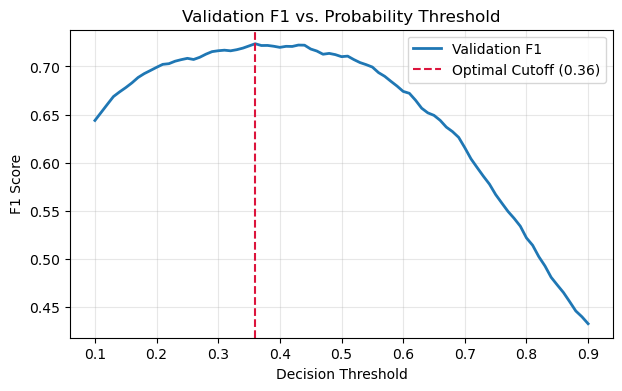

In [6]:
val_probs = best_model.predict_proba(val_pool)[:, 1]

#Search across probability thresholds from 0.10 to 0.90 to balance class imbalance
thresholds = np.linspace(0.10, 0.90, 81)
f1_scores = [f1_score(y_val, (val_probs >= t).astype(int)) for t in thresholds]

best_threshold = float(thresholds[np.argmax(f1_scores)])
print(f"Optimal Decision Threshold: {best_threshold:.2f} (Max Val F1: {max(f1_scores):.4f})")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, f1_scores, color='#1f77b4', lw=2, label='Validation F1')
plt.axvline(best_threshold, color='crimson', linestyle='--', label=f'Optimal Cutoff ({best_threshold:.2f})')
plt.title("Validation F1 vs. Probability Threshold")
plt.xlabel("Decision Threshold")
plt.ylabel("F1 Score")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

FINAL TEST SET EVALUATION (Threshold = 0.36)
ROC-AUC:   0.9313
Accuracy:  0.8632
Precision: 0.6910
Recall:    0.7749
F1-Score:  0.7305

Confusion Matrix: TN=6616, FP=810, FN=526, TP=1811

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.93      0.89      0.91      7426
        >50K       0.69      0.77      0.73      2337

    accuracy                           0.86      9763
   macro avg       0.81      0.83      0.82      9763
weighted avg       0.87      0.86      0.87      9763



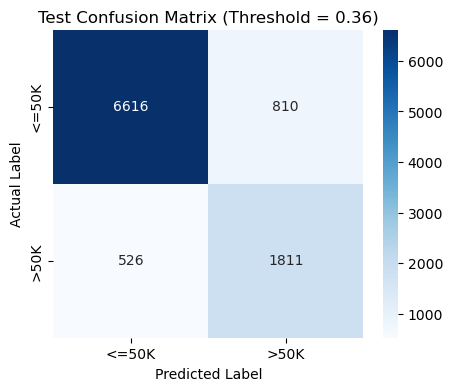

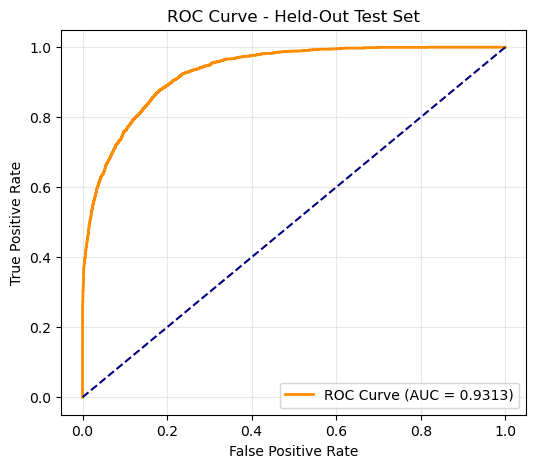

In [7]:
test_probs = best_model.predict_proba(test_pool)[:, 1]
test_preds = (test_probs >= best_threshold).astype(int)

test_auc = roc_auc_score(y_test, test_probs)
test_acc = accuracy_score(y_test, test_preds)
test_prec = precision_score(y_test, test_preds)
test_rec = recall_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()

print("=" * 55)
print(f"FINAL TEST SET EVALUATION (Threshold = {best_threshold:.2f})")
print("=" * 55)
print(f"ROC-AUC:   {test_auc:.4f}")
print(f"Accuracy:  {test_acc:.4f}")
print(f"Precision: {test_prec:.4f}")
print(f"Recall:    {test_rec:.4f}")
print(f"F1-Score:  {test_f1:.4f}")
print(f"\nConfusion Matrix: TN={tn}, FP={fp}, FN={fn}, TP={tp}")
print("\nClassification Report:")
print(classification_report(y_test, test_preds, target_names=['<=50K', '>50K']))

# Visual Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['<=50K', '>50K'], yticklabels=['<=50K', '>50K'])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title(f"Test Confusion Matrix (Threshold = {best_threshold:.2f})")
plt.show()

# Visual ROC Curve
fpr, tpr, _ = roc_curve(y_test, test_probs)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC Curve (AUC = {test_auc:.4f})')
plt.plot([0, 1], [0, 1], color='navy', linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Held-Out Test Set")
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
test_audit = X_test.copy()
test_audit['actual'] = y_test.values
test_audit['prob'] = test_probs
test_audit['pred'] = test_preds

def evaluate_subgroup_parity(data, group_feature):
    records = []
    for group_val, sub in data.groupby(group_feature):
        auc = roc_auc_score(sub['actual'], sub['prob']) if sub['actual'].nunique() > 1 else np.nan
        cm = confusion_matrix(sub['actual'], sub['pred'], labels=[0, 1])
        s_tn, s_fp, s_fn, s_tp = cm.ravel()
        
        tpr = s_tp / (s_tp + s_fn) if (s_tp + s_fn) > 0 else 0.0
        fpr = s_fp / (s_fp + s_tn) if (s_fp + s_tn) > 0 else 0.0
        fnr = s_fn / (s_tp + s_fn) if (s_tp + s_fn) > 0 else 0.0
        
        records.append({
            'Group': group_val,
            'Count': len(sub),
            '>50K Rate': f"{sub['actual'].mean() * 100:.1f}%",
            'ROC-AUC': round(auc, 4),
            'Recall (TPR)': round(tpr, 4),
            'FPR': round(fpr, 4),
            'FNR': round(fnr, 4)
        })
    return pd.DataFrame(records)

print("--- Fairness Audit by Sex ---")
print(evaluate_subgroup_parity(test_audit, 'sex').to_string(index=False))

print("\n--- Fairness Audit by Race ---")
print(evaluate_subgroup_parity(test_audit, 'race').to_string(index=False))

--- Fairness Audit by Sex ---
 Group  Count >50K Rate  ROC-AUC  Recall (TPR)    FPR    FNR
Female   3280     11.7%   0.9491        0.6841 0.0297 0.3159
  Male   6483     30.1%   0.9141        0.7927 0.1599 0.2073

--- Fairness Audit by Race ---
             Group  Count >50K Rate  ROC-AUC  Recall (TPR)    FPR    FNR
Amer-Indian-Eskimo    102     15.7%   0.9121        0.7500 0.1047 0.2500
Asian-Pac-Islander    304     26.0%   0.9192        0.8608 0.1778 0.1392
             Black    907     12.7%   0.9530        0.6261 0.0265 0.3739
             Other     81     11.1%   0.9784        0.5556 0.0139 0.4444
             White   8369     25.3%   0.9286        0.7809 0.1182 0.2191


In [9]:
best_model.save_model("catboost_income_model.cbm")

cat_cols = [
    'workclass', 'education', 'marital_status', 'occupation',
    'relationship', 'race', 'sex', 'native_country'
]
num_cols = [
    'age', 'fnlwgt', 'education_num', 'capital_gain',
    'capital_loss', 'hours_per_week'
]

meta = {
    'threshold': float(best_threshold),
    'cat_cols': cat_cols,
    'num_cols': num_cols,
    'params': best_params,
    'metrics': {
        'auc': round(float(test_auc), 4),
        'f1': round(float(test_f1), 4),
        'acc': round(float(test_acc), 4),
        'prec': round(float(test_prec), 4),
        'rec': round(float(test_rec), 4)
    }
}

with open("model_metadata.json", "w") as f:
    json.dump(meta, f, indent=2)

print("saved model and metadata successfully.")

saved model and metadata successfully.


In [11]:
loaded_model = CatBoostClassifier()
loaded_model.load_model("catboost_income_model.cbm")

with open("model_metadata.json", "r") as f:
    loaded_meta = json.load(f)

# Safely get keys whether saved as 'threshold' or 'optimal_threshold'
threshold = loaded_meta.get('threshold', loaded_meta.get('optimal_threshold', 0.5))
cat_cols = loaded_meta.get('cat_cols', loaded_meta.get('cat_features', []))

print("artifacts loaded successfully!")
print(f"threshold: {threshold:.2f}")

sample_df = pd.DataFrame([
    {
        'age': 38,
        'workclass': 'Private',
        'fnlwgt': 215646,
        'education': 'Bachelors',
        'education_num': 13,
        'marital_status': 'Married-civ-spouse',
        'occupation': 'Exec-managerial',
        'relationship': 'Husband',
        'race': 'White',
        'sex': 'Male',
        'capital_gain': 7298,
        'capital_loss': 0,
        'hours_per_week': 45,
        'native_country': 'United-States'
    },
    {
        'age': 22,
        'workclass': 'Private',
        'fnlwgt': 180000,
        'education': 'HS-grad',
        'education_num': 9,
        'marital_status': 'Never-married',
        'occupation': 'Other-service',
        'relationship': 'Own-child',
        'race': 'Black',
        'sex': 'Female',
        'capital_gain': 0,
        'capital_loss': 0,
        'hours_per_week': 25,
        'native_country': 'United-States'
    }
])

for c in cat_cols:
    sample_df[c] = sample_df[c].replace('?', 'Unknown').fillna('Unknown').astype(str)

eval_pool = Pool(sample_df, cat_features=cat_cols)
sample_probs = loaded_model.predict_proba(eval_pool)[:, 1]
sample_preds = (sample_probs >= threshold).astype(int)

sample_df['probability_gt_50k'] = np.round(sample_probs, 4)
sample_df['prediction'] = ['>50K' if p == 1 else '<=50K' for p in sample_preds]

sample_df[['age', 'occupation', 'sex', 'probability_gt_50k', 'prediction']]

artifacts loaded successfully!
threshold: 0.36


,age,occupation,sex,probability_gt_50k,prediction
0,38,Exec-managerial,Male,0.9975,>50K
1,22,Other-service,Female,0.0003,<=50K


In [15]:
MODEL_FILE = "catboost_income_model.cbm"
METADATA_FILE = "model_metadata.json"

def load_artifacts():
    if not os.path.exists(MODEL_FILE) or not os.path.exists(METADATA_FILE):
        raise FileNotFoundError("model or metadata file missing.")
    
    model = CatBoostClassifier()
    model.load_model(MODEL_FILE)
    
    with open(METADATA_FILE, "r") as f:
        meta = json.load(f)
        
    return model, meta

def predict(df_in):
    model, meta = load_artifacts()
    
    threshold = meta.get('optimal_threshold', meta.get('threshold', 0.5))
    cat_cols = meta.get('cat_features', meta.get('cat_cols', []))
    
    df_clean = df_in.copy()
    
    for col in cat_cols:
        if col in df_clean.columns:
            df_clean[col] = df_clean[col].replace('?', 'Unknown').fillna('Unknown').astype(str)
            
    pool = Pool(df_clean, cat_features=cat_cols)
    probs = model.predict_proba(pool)[:, 1]
    preds = (probs >= threshold).astype(int)
    
    df_clean['prob_gt_50k'] = np.round(probs, 4)
    df_clean['prediction'] = np.where(preds == 1, '>50K', '<=50K')
    
    return df_clean

# test single sample
sample = pd.DataFrame([{
    'age': 42,
    'workclass': 'Private',
    'fnlwgt': 159449,
    'education': 'Bachelors',
    'education_num': 13,
    'marital_status': 'Married-civ-spouse',
    'occupation': 'Exec-managerial',
    'relationship': 'Husband',
    'race': 'White',
    'sex': 'Male',
    'capital_gain': 5178,
    'capital_loss': 0,
    'hours_per_week': 40,
    'native_country': 'United-States'
}])

out = predict(sample)
out[['age', 'occupation', 'sex', 'prob_gt_50k', 'prediction']]

,age,occupation,sex,prob_gt_50k,prediction
0,42,Exec-managerial,Male,0.9843,>50K
